**1.Importing Libraries**

In [27]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

**2.Loading Dataset**

In [28]:
data = load_iris()
X = data.data
y = data.target

**3.Spliting the Dataset**

In [29]:
X_train, X_test, y_train,y_test = train_test_split(X,y, test_size=0.3,random_state = 99)

**4.Defining the Model**

In [30]:
clf = DecisionTreeClassifier(random_state=1)

**5.Training the Model**

In [31]:
clf.fit(X_train, y_train)

DecisionTreeClassifier(random_state=1)

**6.Making Prediction**

In [32]:
y_pred = clf.predict(X_test)
accuracy = accuracy_score(y_pred,y_test)
print(f"Accuracy:{accuracy}")

Accuracy:0.9555555555555556


**7.Hyperparameter Tuning with Deecision Tree Classifier using GridSearchCV**

In [33]:
from sklearn.model_selection import GridSearchCV
grid_param = {
    "max_depth":range(1,10,1),
    "min_samples_leaf":range(1,20,2),
    "min_samples_split":range(2,20,2),
    "criterion":["entropy", "gini"]
}
tree = DecisionTreeClassifier(random_state=1)
grid_search= GridSearchCV(param_grid = grid_param, cv = 5, verbose=True, estimator=tree)
grid_search.fit(X_train, y_train)
print("best accuracy:",grid_search.best_score_)
print(grid_search.best_estimator_)

Fitting 5 folds for each of 1620 candidates, totalling 8100 fits
best accuracy: 0.9714285714285715
DecisionTreeClassifier(criterion='entropy', max_depth=4, min_samples_leaf=3,
                       random_state=1)


**8. Visualizing the Decision Tree Classifier**

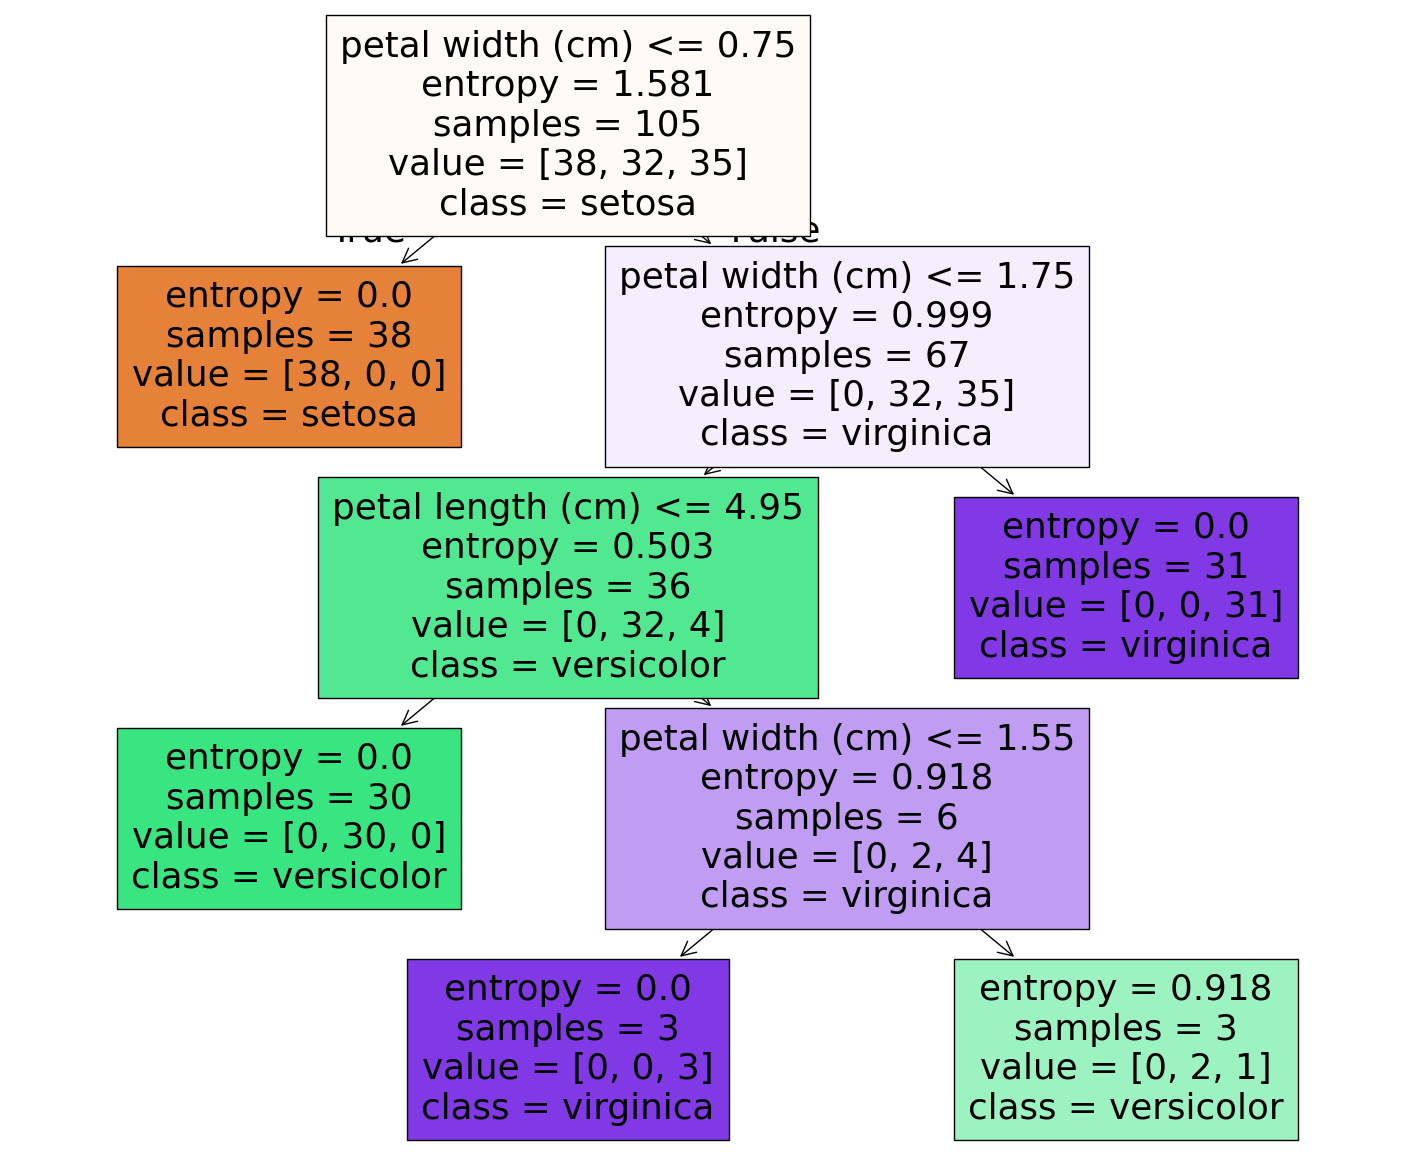

In [38]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
iris = load_iris()
tree_clf = grid_search.best_estimator_
plt.figure(figsize=(18,15))
plot_tree(tree_clf, filled=True, feature_names=iris.feature_names, class_names=iris.target_names)
plt.show()

We can see that it start from the root node (depth 0 at the top).

The root node checks whether the flower petal width is less than or equal to 0.75. If it is then we move to the root's left child node (depth1, left). Here the left node doesn't have any child nodes so the classifier will predict the class for that node as setosa.

If the petal width is greater than 0.75 then we must move down to the root's right child node (depth 1, right). Here the right node is not a leaf node, so node check for the condition until it reaches the leaf node.